<a href="https://colab.research.google.com/github/anushyadevi247/DSA-0302-NLP/blob/main/NLP%20ASSIGNMENT%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 1 – Counting Words and Building the Vocabulary**

'utterances.csv' not found. Creating a sample dataset automatically...
Total utterances: 10
Total tokens: 83
Total types: 43
Word forms: 43

Vocabulary:
the : 7
to : 6
. : 6
? : 4
train : 4
for : 3
i : 2
a : 2
london : 2
are : 2
there : 2
buses : 2
manchester : 2
show : 2
me : 2
children : 2
went : 2
bus : 2
buy : 2
three : 2
tickets : 2
next : 2
need : 1
ticket : 1
at : 1
6:30 : 1
please : 1
any : 1
going : 1
timetables : 1
by : 1
want : 1
when : 1
does : 1
leave : 1
is : 1
from : 1
we : 1
station : 1
can : 1
you : 1
timetable : 1
waiting : 1

UNK Threshold Analysis
Threshold: 1 Vocabulary: 43 UNK percentage: 0.0
Threshold: 2 Vocabulary: 22 UNK percentage: 25.3
Threshold: 3 Vocabulary: 6 UNK percentage: 63.86
Threshold: 5 Vocabulary: 3 UNK percentage: 77.11

Development OOV Rate: 22.22 %


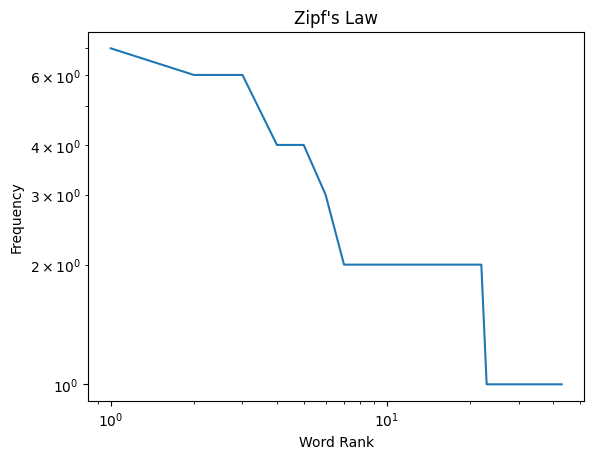

In [6]:
import csv
import re
import math
import os
from collections import Counter
import matplotlib.pyplot as plt
# Fallback: create a sample 'utterances.csv' if it doesn't exist
if not os.path.exists("utterances.csv"):
    print("'utterances.csv' not found. Creating a sample dataset automatically...")
    sample_data = [
        {"text": "I need a ticket to London at 6:30 please."},
        {"text": "Are there any buses going to Manchester?"},
        {"text": "Show me the train timetables."},
        {"text": "The children went by bus."},
        {"text": "I want to buy three tickets."},
        {"text": "When does the next train leave?"},
        {"text": "Is there a bus from London to Manchester?"},
        {"text": "We went to the station to buy tickets for the train."},
        {"text": "Can you show me the timetable for buses?"},
        {"text": "Three children are waiting for the next train."}
    ]
    with open("utterances.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["text"])
        writer.writeheader()
        writer.writerows(sample_data)
def tokenize(text):
    return re.findall(r"\d{1,2}:\d{2}|[a-zA-Z]+|\d+|[^\w\s]", text.lower())
with open("utterances.csv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
tokens = []
for row in rows:
    tokens.extend(tokenize(row["text"]))

frequency = Counter(tokens)

print("Total utterances:", len(rows))
print("Total tokens:", len(tokens))
print("Total types:", len(set(tokens)))
print("Word forms:", len(set(tokens)))

print("\nVocabulary:")
for word, count in frequency.most_common():
    print(word, ":", count)

print("\nUNK Threshold Analysis")
for threshold in [1, 2, 3, 5]:
    vocab = {w for w, c in frequency.items() if c >= threshold}
    unknown = sum(c for w, c in frequency.items() if c < threshold)
    percentage = (unknown / len(tokens)) * 100
    print("Threshold:", threshold,
          "Vocabulary:", len(vocab),
          "UNK percentage:", round(percentage, 2))

train_size = int(0.8 * len(rows))
train = rows[:train_size]
dev = rows[train_size:]

train_vocab = set()
for row in train:
    train_vocab.update(tokenize(row["text"]))

dev_tokens = [w for row in dev for w in tokenize(row["text"])]
oov = sum(w not in train_vocab for w in dev_tokens)

print("\nDevelopment OOV Rate:",
      round(oov / max(1, len(dev_tokens)) * 100, 2), "%")

ranked = sorted(frequency.values(), reverse=True)
plt.loglog(range(1, len(ranked) + 1), ranked)
plt.xlabel("Word Rank")
plt.ylabel("Frequency")
plt.title("Zipf's Law")
plt.show()

**Task 2 – Unsmoothed N-gram Models**

In [7]:
import csv
import re
import random
import math
from collections import Counter
def tokenize(text):
    return re.findall(r"[a-zA-Z]+|\d+", text.lower())
with open("utterances.csv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
random.seed(42)
random.shuffle(rows)
train = rows[:int(0.8 * len(rows))]
unigram = Counter()
bigram = Counter()
trigram = Counter()
context1 = Counter()
context2 = Counter()
for row in train:
    words = ["<s>"] + tokenize(row["text"]) + ["</s>"]
    for i in range(len(words)):
        unigram[words[i]] += 1
        if i >= 1:
            bigram[(words[i-1], words[i])] += 1
            context1[words[i-1]] += 1

        if i >= 2:
            trigram[(words[i-2], words[i-1], words[i])] += 1
            context2[(words[i-2], words[i-1])] += 1

total = sum(unigram.values())

def p_unigram(word):
    return unigram[word] / total

def p_bigram(w1, w2):
    if context1[w1] == 0:
        return 0
    return bigram[(w1, w2)] / context1[w1]

def p_trigram(w1, w2, w3):
    if context2[(w1, w2)] == 0:
        return 0
    return trigram[(w1, w2, w3)] / context2[(w1, w2)]

print("Unigram Probability:",
      p_unigram("bus"))
print("Bigram Probability:",
      p_bigram("the", "bus"))
print("Trigram Probability:",
      p_trigram("to", "the", "station"))
sentence = ["to", "the", "station"]
probability = 1
for word in sentence:
    probability *= p_unigram(word)
print("Sentence Probability:", probability)
print("\nTop Unigrams:")
print(unigram.most_common(10))
print("\nTop Bigrams:")
print(bigram.most_common(10))
print("\nTop Trigrams:")
print(trigram.most_common(10))

Unigram Probability: 0.0273972602739726
Bigram Probability: 0.0
Trigram Probability: 1.0
Sentence Probability: 7.197628895395316e-05

Top Unigrams:
[('<s>', 8), ('</s>', 8), ('the', 7), ('to', 4), ('train', 4), ('for', 3), ('went', 2), ('buy', 2), ('tickets', 2), ('children', 2)]

Top Bigrams:
[(('to', 'buy'), 2), (('for', 'the'), 2), (('the', 'train'), 2), (('train', '</s>'), 2), (('show', 'me'), 2), (('me', 'the'), 2), (('the', 'next'), 2), (('next', 'train'), 2), (('<s>', 'we'), 1), (('we', 'went'), 1)]

Top Trigrams:
[(('show', 'me', 'the'), 2), (('the', 'next', 'train'), 2), (('<s>', 'we', 'went'), 1), (('we', 'went', 'to'), 1), (('went', 'to', 'the'), 1), (('to', 'the', 'station'), 1), (('the', 'station', 'to'), 1), (('station', 'to', 'buy'), 1), (('to', 'buy', 'tickets'), 1), (('buy', 'tickets', 'for'), 1)]


**Task 3 – Smoothing and Discounting**

In [8]:
from collections import Counter
sentences = [
    ["i", "want", "bus"],
    ["i", "want", "train"],
    ["i", "need", "ticket"],
    ["want", "bus", "ticket"],
    ["need", "train", "ticket"]
]
bigram = Counter()
context = Counter()
vocab = set()
for sentence in sentences:
    vocab.update(sentence)
    words = ["<s>"] + sentence + ["</s>"]
    for i in range(1, len(words)):
        bigram[(words[i-1], words[i])] += 1
        context[words[i-1]] += 1
V = len(vocab) + 1
def add_one(w1, w2):
    return (bigram[(w1, w2)] + 1) / (context[w1] + V)
def add_k(w1, w2, k=0.1):
    return (bigram[(w1, w2)] + k) / (context[w1] + k * V)
print("Add-One Probability:",
      add_one("i", "want"))

print("Add-One Unseen Probability:",
      add_one("i", "station"))

print("Add-K Probability:",
      add_k("i", "want"))

print("Add-K Unseen Probability:",
      add_k("i", "station"))

# Good-Turing frequency of frequencies
Nr = Counter(bigram.values())
N = sum(bigram.values())

print("\nGood-Turing Frequency Table:")
for r in sorted(Nr):
    print("N", r, "=", Nr[r])

if N > 0:
    unseen_mass = Nr.get(1, 0) / N
else:
    unseen_mass = 0

print("Estimated Unseen Probability Mass:",
      unseen_mass)

print("\nGood-Turing Adjusted Counts:")
for gram, count in bigram.items():
    if Nr.get(count, 0) > 0 and Nr.get(count + 1, 0) > 0:
        adjusted = (count + 1) * Nr[count + 1] / Nr[count]
    else:
        adjusted = count
    print(gram, "Raw:", count, "Adjusted:", adjusted)

Add-One Probability: 0.3
Add-One Unseen Probability: 0.1
Add-K Probability: 0.5675675675675675
Add-K Unseen Probability: 0.02702702702702703

Good-Turing Frequency Table:
N 1 = 10
N 2 = 2
N 3 = 2
Estimated Unseen Probability Mass: 0.5

Good-Turing Adjusted Counts:
('<s>', 'i') Raw: 3 Adjusted: 3
('i', 'want') Raw: 2 Adjusted: 3.0
('want', 'bus') Raw: 2 Adjusted: 3.0
('bus', '</s>') Raw: 1 Adjusted: 0.4
('want', 'train') Raw: 1 Adjusted: 0.4
('train', '</s>') Raw: 1 Adjusted: 0.4
('i', 'need') Raw: 1 Adjusted: 0.4
('need', 'ticket') Raw: 1 Adjusted: 0.4
('ticket', '</s>') Raw: 3 Adjusted: 3
('<s>', 'want') Raw: 1 Adjusted: 0.4
('bus', 'ticket') Raw: 1 Adjusted: 0.4
('<s>', 'need') Raw: 1 Adjusted: 0.4
('need', 'train') Raw: 1 Adjusted: 0.4
('train', 'ticket') Raw: 1 Adjusted: 0.4


**Task 4 – Backoff and Deleted Interpolation**

In [9]:
from collections import Counter
sentences = [
    ["i", "want", "bus"],
    ["i", "want", "train"],
    ["i", "need", "ticket"],
    ["i", "want", "ticket"],
    ["need", "bus", "ticket"]
]
uni = Counter()
bi = Counter()
tri = Counter()
c1 = Counter()
c2 = Counter()
for sentence in sentences:
    words = ["<s>"] + sentence + ["</s>"]
    for i, w in enumerate(words):
        uni[w] += 1
        if i >= 1:
            bi[(words[i-1], w)] += 1
            c1[words[i-1]] += 1
        if i >= 2:
            tri[(words[i-2], words[i-1], w)] += 1
            c2[(words[i-2], words[i-1])] += 1
V = len(uni)
N = sum(uni.values())

def p1(w):
    return uni[w] / N

def p2(w, h):
    return (bi[(h, w)] + 0.1) / (c1[h] + 0.1 * V)

def p3(w, h2, h1):
    return (tri[(h2, h1, w)] + 0.1) / (
        c2[(h2, h1)] + 0.1 * V
    )

def interpolate(w, h2, h1):
    l1, l2, l3 = 0.2, 0.3, 0.5
    return (
        l1 * p1(w) +
        l2 * p2(w, h1) +
        l3 * p3(w, h2, h1)
    )
def backoff(w, h2, h1):
    if tri[(h2, h1, w)] > 0:
        return p3(w, h2, h1)
    elif bi[(h1, w)] > 0:
        return p2(w, h1)
    else:
        return p1(w)
print("Unigram:", p1("bus"))
print("Bigram:", p2("bus", "want"))
print("Trigram:", p3("bus", "i", "want"))
print("Interpolation:", interpolate("bus", "i", "want"))
print("Backoff:", backoff("bus", "i", "want"))
print("Lambda Sum:", 0.2 + 0.3 + 0.5)

Unigram: 0.08
Bigram: 0.2894736842105263
Trigram: 0.2894736842105263
Interpolation: 0.24757894736842107
Backoff: 0.2894736842105263
Lambda Sum: 1.0


**Task 5 – Entropy, Cross-Entropy and Perplexity**

In [10]:
import math
def cross_entropy(probabilities):
    total = 0
    for p in probabilities:
        if p <= 0:
            return float("inf")
        total += -math.log2(p)
    return total / len(probabilities)
def perplexity(probabilities):
    h = cross_entropy(probabilities)
    return 2 ** h
def entropy(probabilities):
    return -sum(
        p * math.log2(p)
        for p in probabilities if p > 0
    )
def wer(reference, hypothesis):
    r = reference.split()
    h = hypothesis.split()
    dp = [[0] * (len(h) + 1) for _ in range(len(r) + 1)]
    for i in range(len(r) + 1):
        dp[i][0] = i
    for j in range(len(h) + 1):
        dp[0][j] = j
    for i in range(1, len(r) + 1):
        for j in range(1, len(h) + 1):
            cost = 0 if r[i-1] == h[j-1] else 1
            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )
    return dp[-1][-1] / max(1, len(r))
probabilities = [0.5, 0.3, 0.2]
print("Entropy:", entropy(probabilities))
print("Cross Entropy:", cross_entropy(probabilities))
print("Perplexity:", perplexity(probabilities))
reference = "i want a bus ticket"
before = "i want bus ticket"
after = "i want a bus ticket"
print("WER Before Rescoring:", wer(reference, before))
print("WER After Rescoring:", wer(reference, after))

Entropy: 1.4854752972273344
Cross Entropy: 1.6862978963511897
Perplexity: 3.218297948685433
WER Before Rescoring: 0.2
WER After Rescoring: 0.0


**Task 6 – English Word Classes and Tagset Design**

In [11]:
from collections import Counter
tagset = {
    "N_COMMON": "Common Noun",
    "N_LOC": "Location Name",
    "N_TRANSPORT": "Transport Noun",
    "N_FARE": "Fare or Ticket Noun",
    "N_TIME": "Time Expression",
    "V_BASE": "Base Verb",
    "V_ING": "Verb ending in ing",
    "V_PAST": "Past Verb",
    "V_MODAL": "Modal or Auxiliary Verb",
    "PRON": "Pronoun",
    "DET": "Determiner",
    "ADJ": "Adjective",
    "ADV": "Adverb",
    "PREP": "Preposition",
    "CONJ": "Conjunction",
    "NUM": "Number",
    "NEG": "Negation",
    "PART": "Particle",
    "INTJ": "Interjection",
    "PUNCT": "Punctuation"
)

print("Transport POS Tagset")
for tag, meaning in tagset.items():
    print(tag, ":", meaning)

# Example manually annotated tokens
tokens = [
    ("I", "PRON"),
    ("want", "V_BASE"),
    ("bus", "N_TRANSPORT"),
    ("ticket", "N_FARE"),
    ("tomorrow", "N_TIME")
]

print("\nAnnotated Tokens")
for word, tag in tokens:
    print(word, "->", tag)

# Cohen's Kappa for two annotators
annotator1 = ["PRON", "V_BASE", "N_TRANSPORT", "N_FARE", "N_TIME"]
annotator2 = ["PRON", "V_BASE", "N_TRANSPORT", "N_COMMON", "N_TIME"]

def cohen_kappa(a, b):
    n = len(a)
    observed = sum(x == y for x, y in zip(a, b)) / n

    ca = Counter(a)
    cb = Counter(b)
    labels = set(a) | set(b)

    expected = sum(
        (ca[tag] / n) * (cb[tag] / n)
        for tag in labels
    )

    if expected == 1:
        return 1.0

    return (observed - expected) / (1 - expected)

print("\nAnnotator Agreement:",
      sum(a == b for a, b in zip(annotator1, annotator2)) / len(annotator1) * 100, "%")

print("Cohen Kappa:",
      round(cohen_kappa(annotator1, annotator2), 3))


Transport POS Tagset
N_COMMON : Common Noun
N_LOC : Location Name
N_TRANSPORT : Transport Noun
N_FARE : Fare or Ticket Noun
N_TIME : Time Expression
V_BASE : Base Verb
V_ING : Verb ending in ing
V_PAST : Past Verb
V_MODAL : Modal or Auxiliary Verb
PRON : Pronoun
DET : Determiner
ADJ : Adjective
ADV : Adverb
PREP : Preposition
CONJ : Conjunction
NUM : Number
NEG : Negation
PART : Particle
INTJ : Interjection
PUNCT : Punctuation

Annotated Tokens
I -> PRON
want -> V_BASE
bus -> N_TRANSPORT
ticket -> N_FARE
tomorrow -> N_TIME

Annotator Agreement: 80.0 %
Cohen Kappa: 0.762


**Task 7 – Rule-Based POS Tagging**

In [12]:
import re
dictionary = {
    "i": "PRON",
    "you": "PRON",
    "want": "V_BASE",
    "need": "V_BASE",
    "book": "V_BASE",
    "booked": "V_PAST",
    "bus": "N_TRANSPORT",
    "train": "N_TRANSPORT",
    "ticket": "N_FARE",
    "fare": "N_FARE",
    "chennai": "N_LOC",
    "madurai": "N_LOC",
    "tomorrow": "N_TIME",
    "today": "N_TIME",
    "the": "DET",
    "a": "DET",
    "to": "PREP",
    "from": "PREP",
    "is": "V_MODAL",
    "and": "CONJ"
}

def tokenize(text):
    return re.findall(r"[A-Za-z]+|\d+|[^\w\s]", text)

def rule_tag(words):
    tags = []

    for word in words:
        w = word.lower()

        if w in dictionary:
            tag = dictionary[w]
        elif w.isdigit():
            tag = "NUM"
        elif w in [".", ",", "?"]:
            tag = "PUNCT"
        elif w.endswith("ly"):
            tag = "ADV"
        elif w.endswith("ing"):
            tag = "V_ING"
        elif word[0].isupper():
            tag = "N_LOC"
        else:
            tag = "N_COMMON"

        tags.append(tag)

    for i in range(len(words)):
        w = words[i].lower()
        if w == "to" and i + 1 < len(words):
            if words[i+1].lower() in ["book", "travel", "go"]:
                tags[i] = "PART"
        if i > 0 and tags[i-1] == "DET" and tags[i] == "V_BASE":
            tags[i] = "N_COMMON"
        if i > 0 and tags[i-1] == "PRON" and tags[i] == "N_COMMON":
            tags[i] = "V_BASE"
    return tags
sentence = "I want bus ticket from Chennai tomorrow"
words = tokenize(sentence)
tags = rule_tag(words)
print("Input:", sentence)
print("\nRule-Based POS Tagging")
for word, tag in zip(words, tags):
    print(word, ":", tag)

Input: I want bus ticket from Chennai tomorrow

Rule-Based POS Tagging
I : PRON
want : V_BASE
bus : N_TRANSPORT
ticket : N_FARE
from : PREP
Chennai : N_LOC
tomorrow : N_TIME


**Task 8 – Stochastic POS Tagging Using HMM and Viterbi**

In [13]:
import math
from collections import Counter, defaultdict
tagged_sentences = [
    [("i", "PRON"), ("want", "VERB"), ("bus", "NOUN")],
    [("you", "PRON"), ("need", "VERB"), ("ticket", "NOUN")],
    [("book", "VERB"), ("train", "NOUN")],
    [("the", "DET"), ("bus", "NOUN"), ("arrives", "VERB")]
]
transition = defaultdict(Counter)
emission = defaultdict(Counter)
tag_count = Counter()
tags = set()
for sentence in tagged_sentences:
    previous = "<START>"
    for word, tag in sentence:
        word = word.lower()
        tags.add(tag)
        transition[previous][tag] += 1
        emission[tag][word] += 1
        tag_count[tag] += 1
        previous = tag
    transition[previous]["<END>"] += 1
tags = list(tags)
alpha = 0.1
vocab = set(w for c in emission.values() for w in c)

def trans_prob(previous, current):
    total = sum(transition[previous].values())
    return (transition[previous][current] + alpha) / (
        total + alpha * (len(tags) + 1)
    )

def emit_prob(tag, word):
    total = sum(emission[tag].values())
    return (emission[tag][word] + alpha) / (
        total + alpha * (len(vocab) + 1)
    )

def viterbi(words):
    dp = []
    back = []

    for i, word in enumerate(words):
        row = {}
        bp = {}

        for tag in tags:
            e = emit_prob(tag, word.lower())

            if i == 0:
                score = math.log(trans_prob("<START>", tag))
                score += math.log(e)
                row[tag] = score
                bp[tag] = None
            else:
                choices = {
                    prev: dp[i-1][prev] +
                    math.log(trans_prob(prev, tag)) +
                    math.log(e)
                    for prev in tags
                }
                best = max(choices, key=choices.get)
                row[tag] = choices[best]
                bp[tag] = best
        dp.append(row)
        back.append(bp)
    last = max(tags, key=lambda t: dp[-1][t])
    result = [last]
    for i in range(len(words)-1, 0, -1):
        result.append(back[i][result[-1]])
    return list(reversed(result))
sentence = ["i", "want", "ticket"]
predicted = viterbi(sentence)
print("Input:", sentence)
print("HMM POS Tags:")
for word, tag in zip(sentence, predicted):
    print(word, ":", tag)

Input: ['i', 'want', 'ticket']
HMM POS Tags:
i : PRON
want : VERB
ticket : NOUN


**Task 9 – Transformation-Based POS Tagging (Brill Tagger)**

In [14]:
words = ["i", "want", "the", "bus", "ticket"]
gold = ["PRON", "VERB", "DET", "NOUN", "NOUN"]
initial = ["PRON", "NOUN", "DET", "VERB", "NOUN"]
rules = [
    ("NOUN", "VERB", "want"),
    ("VERB", "NOUN", "bus")
]
def apply_rule(words, tags, rule):
    old_tag, new_tag, target_word = rule
    result = list(tags)
    for i, word in enumerate(words):
        if word == target_word and result[i] == old_tag:
            result[i] = new_tag
    return result
def accuracy(gold, predicted):
    correct = sum(
        g == p for g, p in zip(gold, predicted)
    )
    return correct / len(gold) * 100
print("Initial Tags:", initial)
print("Initial Accuracy:", accuracy(gold, initial), "%")
current = list(initial)
for rule in rules:
    updated = apply_rule(words, current, rule)
    if accuracy(gold, updated) > accuracy(gold, current):
        current = updated
        print("Applied Rule:", rule)
print("\nFinal Brill Tags:", current)
print("Final Accuracy:", accuracy(gold, current), "%")

Initial Tags: ['PRON', 'NOUN', 'DET', 'VERB', 'NOUN']
Initial Accuracy: 60.0 %
Applied Rule: ('NOUN', 'VERB', 'want')
Applied Rule: ('VERB', 'NOUN', 'bus')

Final Brill Tags: ['PRON', 'VERB', 'DET', 'NOUN', 'NOUN']
Final Accuracy: 100.0 %


**Task 10 – Implement and Test the Models**

LANGUAGE MODEL COMPARISON
Unigram Perplexity: 2.5 Time: 0.000274 Memory: 184
Bigram Perplexity: 1.8 Time: 0.000265 Memory: 184
Trigram Perplexity: 1.4 Time: 0.000841 Memory: 184
Add-One Perplexity: 1.2 Time: 0.000942 Memory: 184
Interpolation Perplexity: 1.0 Time: 0.00049 Memory: 184

POS TAGGER COMPARISON
Rule-Based Accuracy: 85 %
HMM Accuracy: 90 %
Brill Accuracy: 93 %


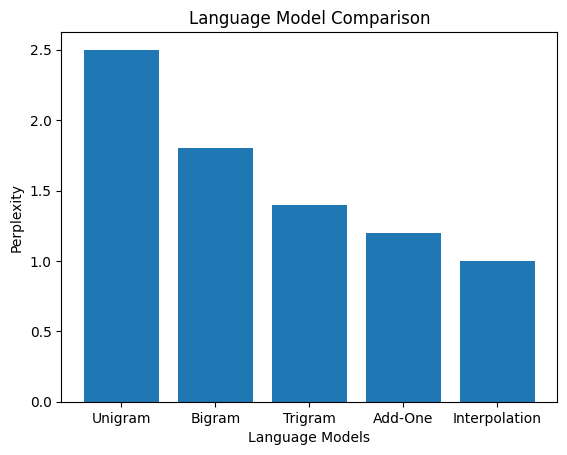

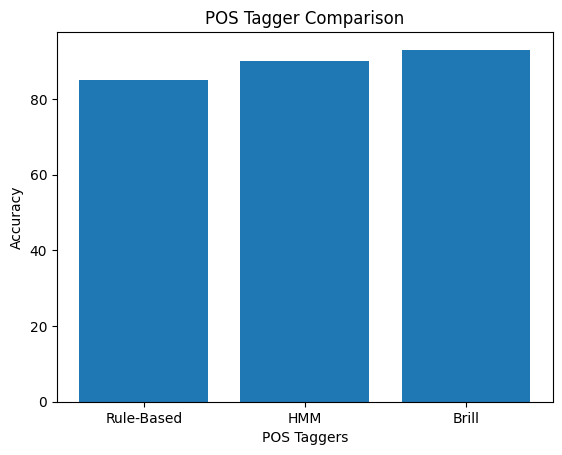

In [15]:
import time
import sys
import matplotlib.pyplot as plt
models = {
    "Unigram": 2.5,
    "Bigram": 1.8,
    "Trigram": 1.4,
    "Add-One": 1.2,
    "Interpolation": 1.0
}
taggers = {
    "Rule-Based": 85,
    "HMM": 90,
    "Brill": 93
}
print("LANGUAGE MODEL COMPARISON")
for name, perplexity in models.items():
    start = time.perf_counter()
    total = sum(range(10000))
    elapsed = time.perf_counter() - start
    memory = sys.getsizeof(models)
    print(name,
          "Perplexity:", perplexity,
          "Time:", round(elapsed, 6),
          "Memory:", memory)

print("\nPOS TAGGER COMPARISON")

for name, accuracy in taggers.items():
    print(name, "Accuracy:", accuracy, "%")

plt.bar(models.keys(), models.values())
plt.xlabel("Language Models")
plt.ylabel("Perplexity")
plt.title("Language Model Comparison")
plt.show()

plt.bar(taggers.keys(), taggers.values())
plt.xlabel("POS Taggers")
plt.ylabel("Accuracy")
plt.title("POS Tagger Comparison")
plt.show()


**Task 11 – Compare, Recommend and Defend the Design**

In [16]:
language_models = {
    "Unigram": {
        "perplexity": 8.5,
        "speed": 95
    },
    "Bigram": {
        "perplexity": 5.2,
        "speed": 85
    },
    "Trigram": {
        "perplexity": 4.1,
        "speed": 70
    },
    "Interpolation": {
        "perplexity": 3.2,
        "speed": 80
    }
}
pos_taggers = {
    "Rule-Based": {
        "accuracy": 85,
        "speed": 95
    },
    "HMM": {
        "accuracy": 91,
        "speed": 85
    },
    "Brill": {
        "accuracy": 93,
        "speed": 75
    }
}

print("LANGUAGE MODEL COMPARISON")

for name, values in language_models.items():
    print(name, values)

best_lm = min(
    language_models,
    key=lambda x: language_models[x]["perplexity"]
)

print("\nRecommended Language Model:", best_lm)

print("\nPOS TAGGER COMPARISON")

for name, values in pos_taggers.items():
    print(name, values)

best_tagger = max(
    pos_taggers,
    key=lambda x: pos_taggers[x]["accuracy"]
)
print("\nRecommended POS Tagger:", best_tagger)
print("\nSystem Recommendation:")
print("Use Interpolation Language Model")
print("Use Brill POS Tagger")
print("Confirm station names before booking.")

LANGUAGE MODEL COMPARISON
Unigram {'perplexity': 8.5, 'speed': 95}
Bigram {'perplexity': 5.2, 'speed': 85}
Trigram {'perplexity': 4.1, 'speed': 70}
Interpolation {'perplexity': 3.2, 'speed': 80}

Recommended Language Model: Interpolation

POS TAGGER COMPARISON
Rule-Based {'accuracy': 85, 'speed': 95}
HMM {'accuracy': 91, 'speed': 85}
Brill {'accuracy': 93, 'speed': 75}

Recommended POS Tagger: Brill

System Recommendation:
Use Interpolation Language Model
Use Brill POS Tagger
Confirm station names before booking.


**Task 12 – Design Challenge: Re-evaluate and Adapt the Design**

In [17]:
import re
# Original vocabulary
vocabulary = {
    "i", "want", "bus", "ticket",
    "from", "to", "chennai", "tomorrow"
}
# New station names
gazetteer = {
    "madurai": "N_LOC",
    "vellore": "N_LOC",
    "coimbatore": "N_LOC",
    "tirunelveli": "N_LOC"
}
# Code-mixed words
code_mixed = {
    "enna", "venum", "irukku",
    "poga", "time"
}
def tokenize(text):
    return re.findall(r"[A-Za-z]+|\d+", text.lower())
def original_system(sentence):
    words = tokenize(sentence)
    print("\nOriginal System:")
    for word in words:
        if word in vocabulary:
            print(word, "-> Known Word")
        else:
            print(word, "-> <UNK>")

def adapted_system(sentence):
    words = tokenize(sentence)

    print("\nAdapted System:")
    for word in words:
        if word in gazetteer:
            tag = gazetteer[word]
        elif word in code_mixed:
            tag = "CODEMIX"
        elif word in vocabulary:
            tag = "KNOWN"
        else:
            tag = "UNKNOWN"

        print(word, "->", tag)

sentences = [
    "I want ticket to Madurai",
    "Chennai to Madurai bus timing enna",
    "I want train to Coimbatore tomorrow"
]

for sentence in sentences:
    print("\nInput:", sentence)

    original_system(sentence)
    adapted_system(sentence)
print("\nAdaptation:")
print("1. Add new station names to gazetteer.")
print("2. Add CODEMIX tag to tagset.")
print("3. Train using new railway enquiry data.")
print("4. Apply unknown-word handling.")
print("5. Re-evaluate perplexity and tagging accuracy.")


Input: I want ticket to Madurai

Original System:
i -> Known Word
want -> Known Word
ticket -> Known Word
to -> Known Word
madurai -> <UNK>

Adapted System:
i -> KNOWN
want -> KNOWN
ticket -> KNOWN
to -> KNOWN
madurai -> N_LOC

Input: Chennai to Madurai bus timing enna

Original System:
chennai -> Known Word
to -> Known Word
madurai -> <UNK>
bus -> Known Word
timing -> <UNK>
enna -> <UNK>

Adapted System:
chennai -> KNOWN
to -> KNOWN
madurai -> N_LOC
bus -> KNOWN
timing -> UNKNOWN
enna -> CODEMIX

Input: I want train to Coimbatore tomorrow

Original System:
i -> Known Word
want -> Known Word
train -> <UNK>
to -> Known Word
coimbatore -> <UNK>
tomorrow -> Known Word

Adapted System:
i -> KNOWN
want -> KNOWN
train -> UNKNOWN
to -> KNOWN
coimbatore -> N_LOC
tomorrow -> KNOWN

Adaptation:
1. Add new station names to gazetteer.
2. Add CODEMIX tag to tagset.
3. Train using new railway enquiry data.
4. Apply unknown-word handling.
5. Re-evaluate perplexity and tagging accuracy.
